# 01 — SciCo Dataset Inspection & Exploratory Analysis

This notebook inspects the locally stored SciCo Parquet files (`Training.parquet`, `Validation.parquet`, `Test.parquet`) using PyArrow and Pandas without modifying the raw dataset files.

Key questions verified here:
1. What are the exact Arrow columns, nested types, and file sizes?
2. Are topic IDs (`id`) strictly disjoint across splits?
3. Are mention spans `[start, end, cluster_id]` 0-based and inclusive or exclusive on `end`?
4. What are the distributions of topics, documents, mentions, gold clusters, mention lengths, and cluster sizes?


In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)
print("Project root:", ROOT)


Project root: E:\AOU\elevvo internship\tusk 4


In [2]:
from src.data_loader import load_config, inspect_parquet_schema, load_all_splits, verify_split_isolation

cfg = load_config(ROOT / "config.yaml")
for key in ("train_parquet", "val_parquet", "test_parquet"):
    info = inspect_parquet_schema(ROOT / cfg["paths"][key])
    print(f"=== {key}: {info['path']} ===")
    print(f"Rows (topics): {info['num_rows']} | Size: {info['file_size_bytes'] / 1e6:.2f} MB")
    display(pd.DataFrame(info["columns"]))


=== train_parquet: E:\AOU\elevvo internship\tusk 4\data\Training.parquet ===
Rows (topics): 221 | Size: 4.96 MB


,name,arrow_type,nullable
0,flatten_tokens,list<item: string>,True
1,flatten_mentions,list<item: fixed_size_list<item: int32>[3]>,True
2,tokens,list<item: list<item: string>>,True
3,doc_ids,list<item: int32>,True
4,metadata,"struct<title: list<item: string>, paper_sha: list<item: string>, fields_of_s...",True
5,sentences,list<item: list<item: list<item: int32>>>,True
6,mentions,list<item: fixed_size_list<item: int32>[4]>,True
7,relations,list<item: fixed_size_list<item: int32>[2]>,True
8,id,int32,True
9,source,string,True


=== val_parquet: E:\AOU\elevvo internship\tusk 4\data\Validation.parquet ===
Rows (topics): 100 | Size: 2.34 MB


,name,arrow_type,nullable
0,flatten_tokens,list<item: string>,True
1,flatten_mentions,list<item: fixed_size_list<item: int32>[3]>,True
2,tokens,list<item: list<item: string>>,True
3,doc_ids,list<item: int32>,True
4,metadata,"struct<title: list<item: string>, paper_sha: list<item: string>, fields_of_s...",True
5,sentences,list<item: list<item: list<item: int32>>>,True
6,mentions,list<item: fixed_size_list<item: int32>[4]>,True
7,relations,list<item: fixed_size_list<item: int32>[2]>,True
8,id,int32,True
9,source,string,True


=== test_parquet: E:\AOU\elevvo internship\tusk 4\data\Test.parquet ===
Rows (topics): 200 | Size: 4.70 MB


,name,arrow_type,nullable
0,flatten_tokens,list<item: string>,True
1,flatten_mentions,list<item: fixed_size_list<item: int32>[3]>,True
2,tokens,list<item: list<item: string>>,True
3,doc_ids,list<item: int32>,True
4,metadata,"struct<title: list<item: string>, paper_sha: list<item: string>, fields_of_s...",True
5,sentences,list<item: list<item: list<item: int32>>>,True
6,mentions,list<item: fixed_size_list<item: int32>[4]>,True
7,relations,list<item: fixed_size_list<item: int32>[2]>,True
8,id,int32,True
9,source,string,True


In [3]:
splits = load_all_splits(cfg)
isolation = verify_split_isolation(splits)
print("Split isolation check:", json.dumps(isolation, indent=2))


Split isolation check: {
  "counts": {
    "train": 221,
    "validation": 100,
    "test": 200
  },
  "overlaps": {},
  "is_disjoint": true
}


In [4]:
# Verify span boundary semantics on real annotated examples
sample_row = splits["train"].iloc[0]
ft = list(sample_row["flatten_tokens"])
fm = [list(x) for x in sample_row["flatten_mentions"]]

print(f"Topic ID: {sample_row['id']} | Source: {sample_row['source']} | Total tokens: {len(ft)}")
print("Checking exclusive [start:end] vs inclusive [start:end+1] on Training topic 0 and topic 1:")
for r_idx in (0, 1):
    r = splits["train"].iloc[r_idx]
    toks = list(r["flatten_tokens"])
    for m_i, (s, e, c) in enumerate(r["flatten_mentions"][:6]):
        print(f"  topic={r['id']} m={m_i} span=({s},{e}) cid={c} | excl={toks[s:e]} | incl={toks[s:e+1]}")


Topic ID: 521 | Source: hypernym | Total tokens: 4198
Checking exclusive [start:end] vs inclusive [start:end+1] on Training topic 0 and topic 1:
  topic=521 m=0 span=(9,10) cid=2 | excl=['software'] | incl=['software', 'development']
  topic=521 m=1 span=(50,52) cid=2 | excl=['software', 'development'] | incl=['software', 'development', 'project']
  topic=521 m=2 span=(85,86) cid=2 | excl=['software'] | incl=['software', 'developing']
  topic=521 m=3 span=(137,138) cid=2 | excl=['software'] | incl=['software', 'developing']
  topic=521 m=4 span=(176,178) cid=2 | excl=['software', 'development'] | incl=['software', 'development', 'purposes']
  topic=521 m=5 span=(218,221) cid=2 | excl=['Software', 'Development', 'Software'] | incl=['Software', 'Development', 'Software', 'development']
  topic=522 m=0 span=(26,27) cid=9 | excl=['routing'] | incl=['routing', 'protocols']
  topic=522 m=1 span=(72,74) cid=9 | excl=['routing', 'layer'] | incl=['routing', 'layer', 'protocol']
  topic=522 m=2 

In [5]:
# Confirm single-token spans where start == end across all splits
for sname, df in splits.items():
    eq_count = sum(1 for _, r in df.iterrows() for s, e, _ in r["flatten_mentions"] if s == e)
    print(f"{sname}: {eq_count} mentions have start == end (proving 0-based inclusive end indexing)")


train: 483 mentions have start == end (proving 0-based inclusive end indexing)
validation: 220 mentions have start == end (proving 0-based inclusive end indexing)
test: 427 mentions have start == end (proving 0-based inclusive end indexing)


In [6]:
# Compute split-level statistics using extracted mentions
from src.mention_extractor import extract_mentions_from_dataframe

summary_rows = []
mention_frames = []
for sname, df in splits.items():
    mdf, _ = extract_mentions_from_dataframe(df, sname, preprocessing_cfg=cfg["preprocessing"])
    mention_frames.append(mdf)
    cluster_sizes = mdf.groupby("cluster_id").size()
    summary_rows.append({
        "split": sname,
        "topics": len(df),
        "snippets": int(sum(len(r["tokens"]) for _, r in df.iterrows())),
        "unique_papers": int(sum(len(set(r["doc_ids"])) for _, r in df.iterrows())),
        "mentions": len(mdf),
        "gold_clusters": int(mdf["cluster_id"].nunique()),
        "mean_mention_len": round(float(mdf["token_length"].mean()), 2),
        "median_mention_len": float(mdf["token_length"].median()),
        "mean_cluster_size": round(float(cluster_sizes.mean()), 2),
        "singleton_clusters_pct": round(float((cluster_sizes == 1).mean() * 100), 2),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)
all_mentions_df = pd.concat(mention_frames, ignore_index=True)


Split 'test' extraction completed: 10423 extracted, 62 doc_tokens_fallback, 0 malformed.


,split,topics,snippets,unique_papers,mentions,gold_clusters,mean_mention_len,median_mention_len,mean_cluster_size,singleton_clusters_pct
0,train,221,10660,10316,10922,4079,3.16,3.0,2.68,61.90
1,validation,100,4781,4609,4873,1747,3.17,3.0,2.79,60.79
2,test,200,10203,9842,10423,3711,3.14,3.0,2.81,61.87


In [7]:
# Inspect representative mention examples
display(all_mentions_df[["split", "topic_id", "paper_id", "mention_id", "mention_text", "token_length", "cluster_id", "parent_cluster_id"]].head(12))


,split,topic_id,paper_id,mention_id,mention_text,token_length,cluster_id,parent_cluster_id
0,train,521,4e576a5a732b5934a0b53c4a3921afb50cc8ce5c,train_t521_m0,software development,2,train::t521::c2,None
1,train,521,697ba413e9c74a593d4a2549a94982a426091965,train_t521_m1,software development project,3,train::t521::c2,None
2,train,521,5d6eb98e013e50b3299a579b99766e8761de39e1,train_t521_m2,software developing,2,train::t521::c2,None
3,train,521,563dd59ed06d725ee140a893d268c3c3a6f16c1a,train_t521_m3,software developing,2,train::t521::c2,None
4,train,521,b58bc9cc0e32d04ef272482d286486e831d48820,train_t521_m4,software development purposes,3,train::t521::c2,None
5,train,521,955a3df3129d87b0207eddbecdb775a97f97113e,train_t521_m5,Software Development Software development,4,train::t521::c2,None
6,train,521,b402d4c2ffe4f22fb682e65308a3360f4fbbf093,train_t521_m6,thesoftware development,2,train::t521::c2,None
7,train,521,078c3c30cc42d33d654e73186dfea9ddf3fd4530,train_t521_m7,requirements elicitation,2,train::t521::c3,train::t521::c2
8,train,521,a7d111ff88cd8ab0718726e1ede355dabfe3c01d,train_t521_m8,requirements elicitation problem,3,train::t521::c3,train::t521::c2
9,train,521,90eb04b92d8a265884e397a43a9d56d893da1140,train_t521_m9,requirements elicitation purposes,3,train::t521::c3,train::t521::c2


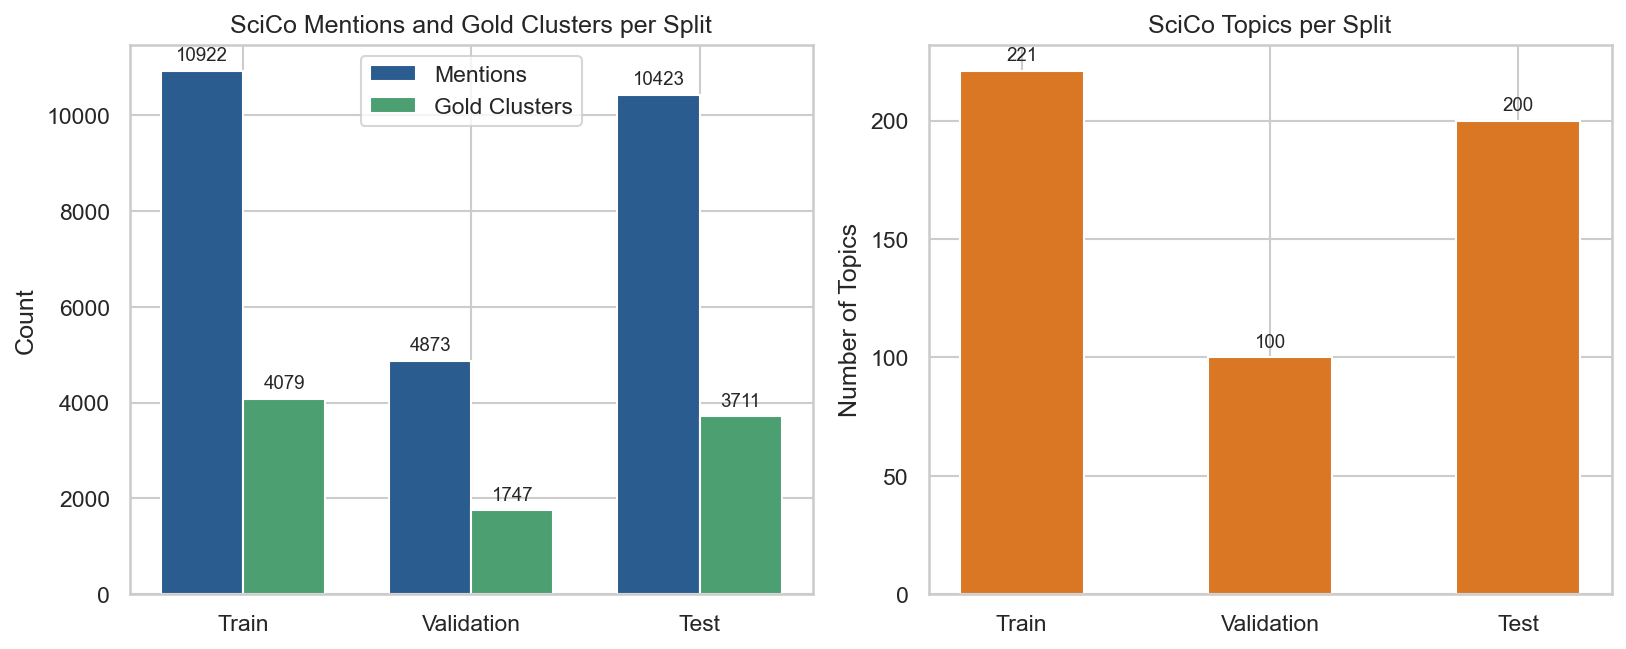

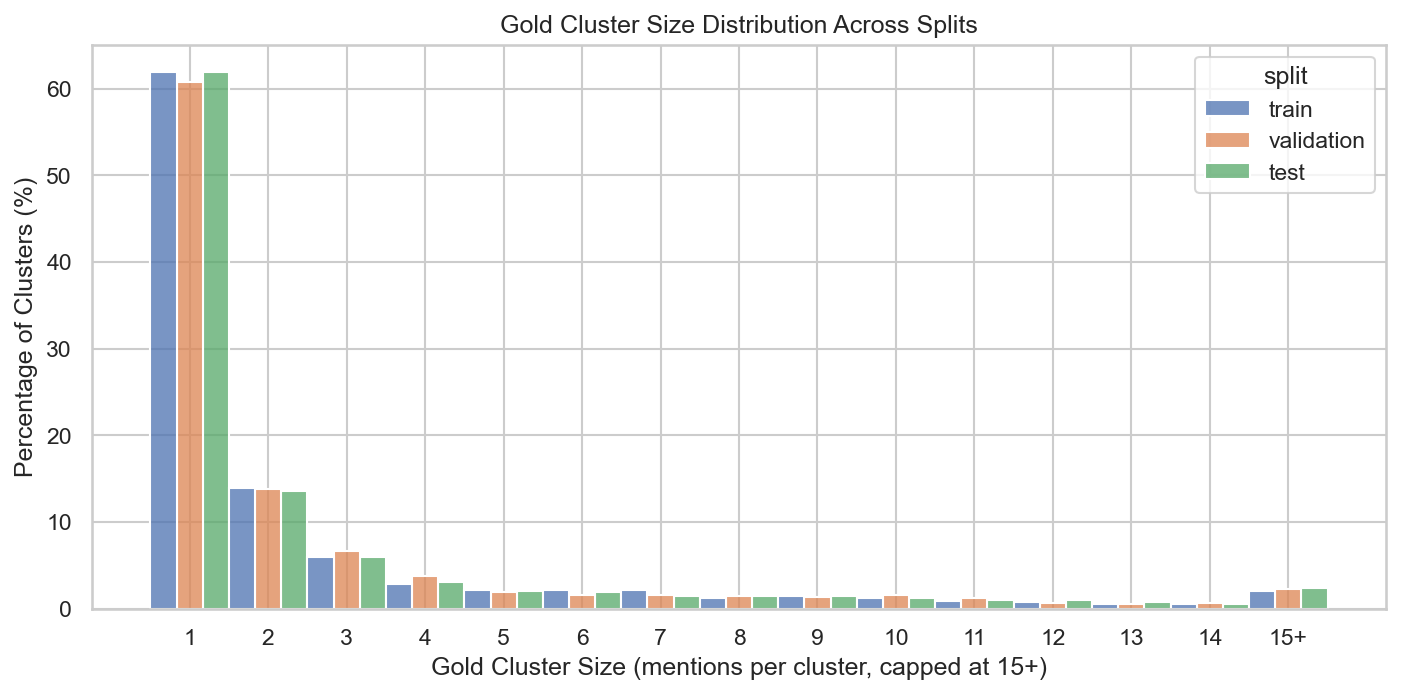

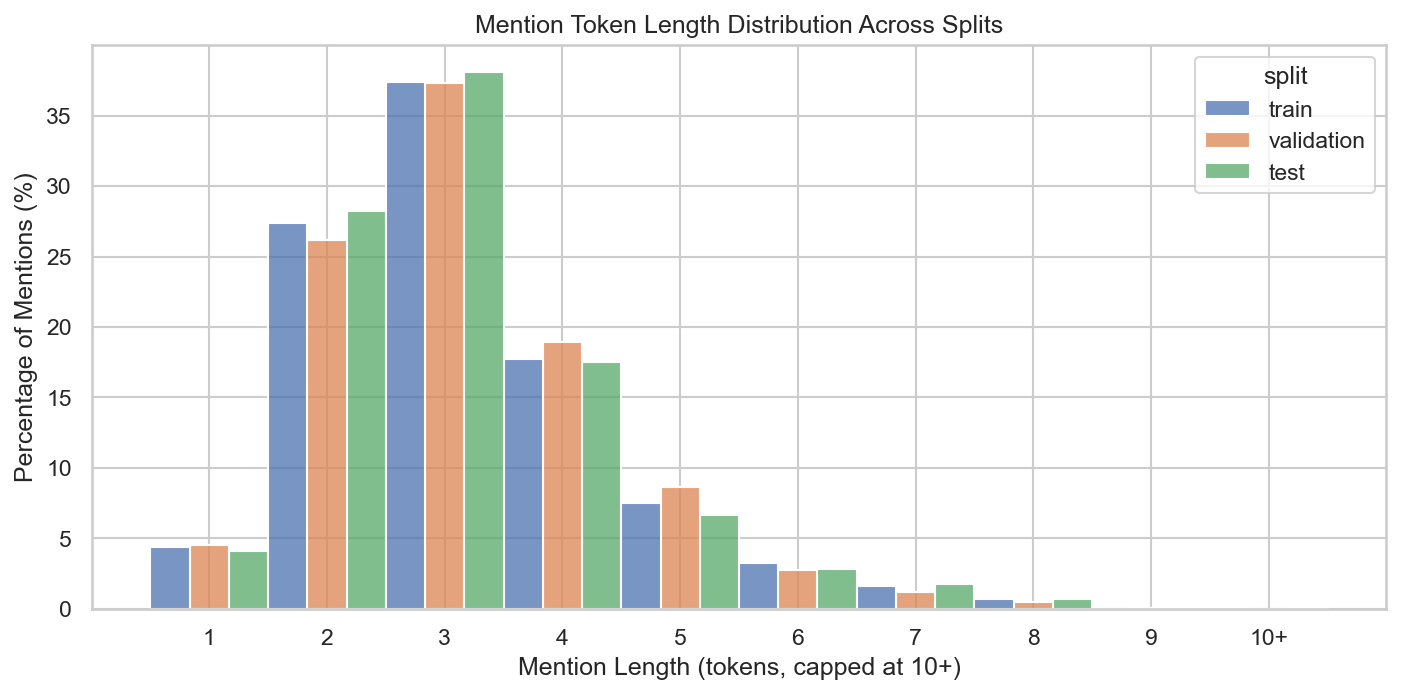

In [8]:
# Display exploratory figures generated by the pipeline
for fig_name in ("01_mentions_per_split.png", "02_cluster_size_distribution.png", "03_mention_length_distribution.png"):
    fig_path = ROOT / cfg["paths"]["figures_dir"] / fig_name
    if fig_path.exists():
        display(Image(filename=str(fig_path)))
